# SWYNEX Task 1: Data Preparation
**Dataset:** IBM Telco Customer Churn (public, 7,043 customers, 21 columns)  
**Business context:** A telecom company wants to predict which customers will cancel. Before any modelling, the data must be trustworthy.  
**Approach:** Exploration happens here; the cleaning logic lives in `src/data_prep.py` (unit-tested), so results are reproducible and the notebook cannot drift from the pipeline.

In [1]:
import sys; sys.path.insert(0, "..")
import pandas as pd
import matplotlib.pyplot as plt
from src import data_prep as dp

pd.set_option("display.max_columns", 30)
raw = dp.load_raw()
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Profile the raw data

In [2]:
raw.dtypes.to_frame("dtype").T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,str,str


In [3]:
print("True NaN cells :", int(raw.isna().sum().sum()))
print("Duplicate rows  :", int(raw.duplicated().sum()))
print("Duplicate IDs   :", int(raw["customerID"].duplicated().sum()))

True NaN cells : 0
Duplicate rows  : 0
Duplicate IDs   : 0


Pandas reports **no** missing values, yet `TotalCharges` is typed as text even though it should be numeric. That mismatch is a red flag worth investigating.

In [4]:
blank = raw["TotalCharges"].str.strip().eq("")
print("Blank TotalCharges:", blank.sum())
raw.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Finding:** every blank belongs to a customer with `tenure = 0`, i.e. a brand-new customer who has not been billed yet. The value is not *unknown*; it is genuinely **0**.

**Decision:** impute `0.0`, not the mean/median (which would fabricate ~$2.3k of revenue per customer). The pipeline raises an error if a blank ever appears with `tenure > 0`, so this assumption is enforced, not just stated.

In [5]:
for c in ["MultipleLines", "OnlineSecurity", "TechSupport", "StreamingTV"]:
    print(c, "->", raw[c].value_counts().to_dict())

MultipleLines -> {'No': 3390, 'Yes': 2971, 'No phone service': 682}
OnlineSecurity -> {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
TechSupport -> {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV -> {'No': 2810, 'Yes': 2707, 'No internet service': 1526}


**Finding:** add-on columns contain a third level ("No internet service" / "No phone service") that merely repeats `InternetService` / `PhoneService`. Keeping it creates redundant, collinear dummies later, so it is collapsed to "No".

## 2. Run the tested pipeline

In [6]:
df, audit = dp.clean(raw)
pd.DataFrame(audit.steps)

,step,detail,rows_affected
0,Rename columns,CamelCase -> snake_case (e.g. customerID -> cu...,0
1,Strip whitespace,Applied to 18 text columns,11
2,Fix type: total_charges,"Blank strings -> NaN, column cast to float64",11
3,Impute: total_charges,All blanks belong to tenure = 0 customers (no ...,11
4,Collapse redundant levels,'No internet service' / 'No phone service' -> ...,9838
5,Encode Yes/No,12 columns -> int8 (1 = Yes),0
6,Set categorical dtypes,"gender, internet_service, payment_method -> ca...",0


In [7]:
pd.DataFrame(dp.validate(df), columns=["check", "passed", "detail"])

,check,passed,detail
0,customer_id is unique,True,7043 unique ids
1,No missing values,True,0 nulls
2,No duplicate rows,True,0 duplicates
3,tenure >= 0,True,range 0-72 months
4,monthly_charges > 0,True,range 18.25-118.75
5,total_charges >= 0,True,min 0.00
6,Binary columns contain only 0/1,True,13 columns
7,Contract levels as expected,True,"Month-to-month, One year, Two year"
8,tenure = 0 <=> total_charges = 0,True,billing history consistent with tenure


In [8]:
df.dtypes.to_frame("dtype").T

,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
dtype,str,category,int8,int8,int8,int16,int8,int8,category,int8,int8,int8,int8,int8,int8,category,int8,category,float64,float64,int8


## 3. Before vs after

In [9]:
pd.DataFrame({
    "raw":   [raw.shape[0], raw.shape[1], int(raw.isna().sum().sum()), int(blank.sum()), round(raw.memory_usage(deep=True).sum()/1e6, 2)],
    "clean": [df.shape[0],  df.shape[1],  int(df.isna().sum().sum()),  0,                 round(df.memory_usage(deep=True).sum()/1e6, 2)],
}, index=["rows", "columns", "NaN cells", "hidden blanks", "memory (MB)"])

,raw,clean
rows,7043.00,7043.00
columns,21.00,21.00
NaN cells,0.00,0.00
hidden blanks,11.00,0.00
memory (MB),7.15,0.66


## 4. Quick sanity visuals (is the cleaned data usable?)

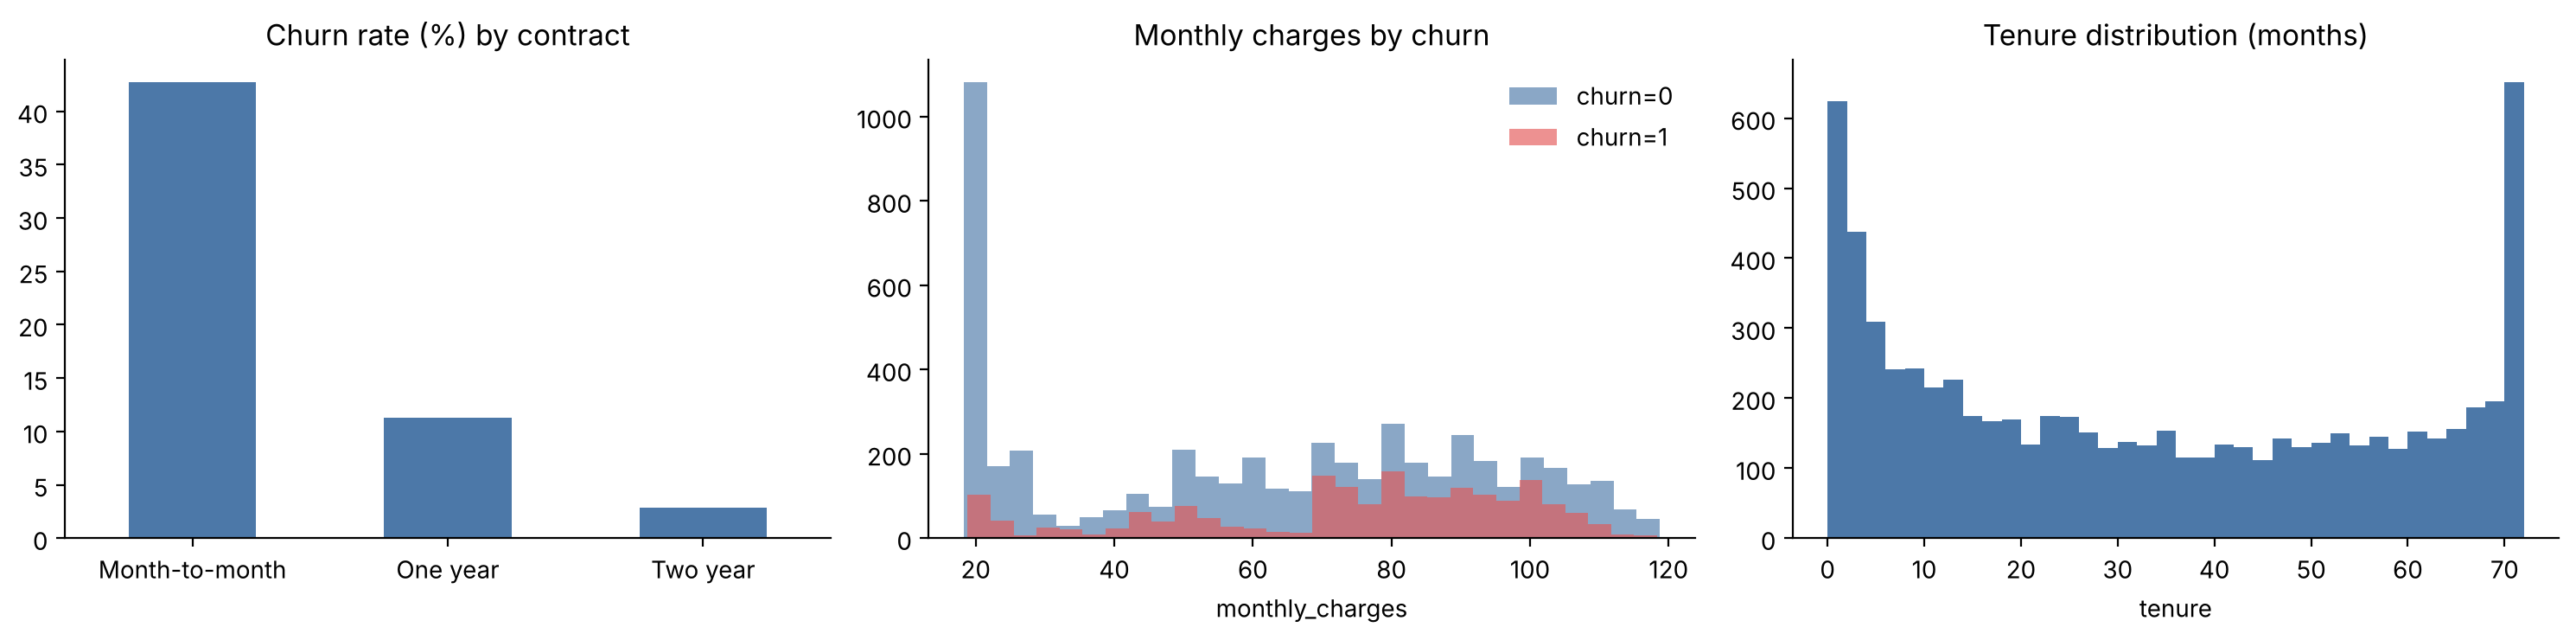

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

df.groupby("contract", observed=True)["churn"].mean().mul(100).plot.bar(ax=ax[0], color="#4C78A8", rot=0)
ax[0].set(title="Churn rate (%) by contract", xlabel="")

for k, color in [(0, "#4C78A8"), (1, "#E45756")]:
    ax[1].hist(df.loc[df["churn"] == k, "monthly_charges"], bins=30, alpha=.65, color=color, label=f"churn={k}")
ax[1].set(title="Monthly charges by churn", xlabel="monthly_charges"); ax[1].legend(frameon=False)

ax[2].hist(df["tenure"], bins=36, color="#4C78A8")
ax[2].set(title="Tenure distribution (months)", xlabel="tenure")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Reading the plots:** month-to-month customers churn far more than contract customers, and churners skew toward higher monthly bills. Both are plausible business patterns, which is a good sign the cleaning preserved real signal.

## 5. Export

In [11]:
dp.CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(dp.CLEAN_PATH, index=False)
print("Saved", dp.CLEAN_PATH.name, df.shape)

Saved telco_churn_clean.csv (7043, 21)


## Assumptions & limitations
1. `total_charges` blanks = 0 only because all affected rows have `tenure = 0` (verified above and enforced in code).
2. No rows were dropped. No IQR outliers were found in `tenure`, `monthly_charges` or `total_charges`.
3. 13 rows show `total_charges` far from `tenure x monthly_charges`; left unchanged and flagged in `reports/data_quality_report.md`.
4. Class balance is about 26.5% churn; use stratified splits when modelling.
5. The dataset is a static public sample; no temporal drift or leakage analysis was possible.